# Results: the PINN against finite differences

This notebook gathers the results of the project. The PINNs (`src/mfg/pinn/`) solve the
mean-field game; the finite-difference solvers (FD, `src/mfg/fd/`) are the reference they are
checked against. All the results use the base parameters of `configs/base.yaml`, with
penalty strength $\lambda = 2$ unless a section says otherwise.

1. **The equilibrium.** The average final wealth $\bar m_T$ that each method finds.
2. **The strategy $\pi^*$.** What the investors do at the equilibrium.
3. **The wealth distribution $m$.** Where the population ends up.
4. **How fast each method converges.** Accuracy against computing time, and the search for $\bar m_T$.
5. **What each part of the loss does.** The parts of the two PINN losses during training.
6. **The strength of the penalty.** How the equilibrium changes with $\lambda$.
7. **Summary.** Accuracy and cost of the two methods.

**How to read the figures.** The PINN is always the **solid blue** line and FD the **dashed
orange** line. Thin grey lines are references, such as the Merton position or the game without
the penalty ($\lambda = 0$).

**Running it.** The first run trains every network, which takes about half an hour on a laptop GPU.
The trained networks are saved in `results/results_notebook/`, which git ignores. Later runs load
them instead of training, and take about a minute: only the FD solves are repeated. Delete that
folder to train again. Each figure is also saved as a PNG in `results/figures/`, for slides.

## Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Find the repository folder from wherever the notebook runs, and use its source code if the
# package is not installed.
ROOT = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / "configs" / "base.yaml").exists())
try:
    import mfg  # noqa: F401
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))

from mfg.benchmarks import merton_pi, population_mean, population_var
from mfg.equilibrium import secant_fixed_point
from mfg.fd import phi as fd_phi
from mfg.fd import solve_equilibrium, solve_hjb
from mfg.params import Params
from mfg.pinn.equilibrium import PinnEquilibriumSettings, pinn_best_response
from mfg.pinn.hjb import ValueNetSettings, train_value_net
from mfg.pinn.nets import pick_device

# A harmless notice PyTorch prints the first time it differentiates on a GPU.
warnings.filterwarnings("ignore", message="Attempting to run cuBLAS")

p = Params.from_yaml(ROOT / "configs" / "base.yaml")  # lam = 2, x in [-1, 3], T = 1
print(p)
print("device:", pick_device())

Params(r=0.02, mu=0.08, sigma=0.2, gamma=1.0, lam=2.0, T=1.0, m0_mean=1.0, m0_std=0.2, x_min=-1.0, x_max=3.0)
device: cuda


In [2]:
# Plot style: thin lines, a light grid, and one colour per method in every figure.
INK, MUTED, BAND = "#0b0b0b", "#898781", "#f0efec"
PINN, FD = "#2a78d6", "#eb6834"  # the PINN: solid blue line; FD: dashed orange line
FD_LINE = (0, (5, 3))  # the dash of every FD line
LOSS_COLOURS = {  # one colour per part of the losses, the same in both networks
    "equation": "#6250d6",
    "terminal": "#1baf7a",
    "slopes": "#eda100",
    "edges": "#e87ba4",
    "mass": "#008300",
}
LAMBDA_RAMP = ["#f0a070", "#eb6834", "#a8421a", "#6e2a0c"]  # FD at lam = 1, 2, 5, 10: light = weak
LESS_MORE = LinearSegmentedColormap.from_list("less_more", ["#1c5cab", BAND, "#e34948"])
DOT = {"marker": "o", "ms": 7, "mec": "white", "mew": 1.5}  # dots with a white ring
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.grid": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "axes.titlesize": 11,
        "axes.titlelocation": "left",
        "axes.labelcolor": "#52514e",
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "lines.linewidth": 1.8,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)

CACHE = ROOT / "results" / "results_notebook"  # trained networks; delete the folder to retrain
FIGURES = ROOT / "results" / "figures"  # PNG copies of the figures


def cached(name, compute):
    """Run compute() and save its result in CACHE; if it is already saved, load it instead."""
    path = CACHE / f"{name}.pt"
    if path.exists():
        return torch.load(path, map_location=pick_device(), weights_only=False)
    result = compute()
    CACHE.mkdir(parents=True, exist_ok=True)
    torch.save(result, path)
    return result


def timed(compute):
    """The result of compute() and the seconds it took."""
    start = time.perf_counter()
    result = compute()
    return result, time.perf_counter() - start


def save(fig, name):
    """Keep a PNG copy of the figure in results/figures/."""
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")


def show_table(header, rows):
    """Show a table: a list of column titles and a list of rows, all strings."""
    lines = ["| " + " | ".join(header) + " |", "|" + " --- |" * len(header)]
    lines += ["| " + " | ".join(row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## 1. The equilibrium

Each investor plays against the average final wealth $\bar m$ that they expect. Call
$\Phi(\bar m)$ the average final wealth that comes out when everyone plays their best strategy
against $\bar m$. The equilibrium is the $\bar m$ that reproduces itself: $\Phi(\bar m) = \bar m$.
Both methods look for it with the same secant method (`src/mfg/equilibrium.py`), starting from
the answer without the penalty.

- **FD.** One evaluation of $\Phi$ is an HJB solve and a Fokker–Planck solve on an
  800 × 400 grid (`solve_equilibrium`).
- **PINN.** One evaluation trains three networks: the value network (for $V$ and $\pi^*$), a
  smooth copy of $\pi^*$, and the density network (for $m$). The first evaluation trains them
  from scratch; each later one starts from the networks of the one before and trains briefly.

The cell below is `solve_pinn_equilibrium` written out, with the same settings, so that the
networks of every evaluation are kept: section 5 plots the losses of the first one.

In [3]:
fd_eq, fd_seconds = timed(lambda: solve_equilibrium(p))  # the 800 x 400 grid
fd_fine, fd_fine_seconds = timed(lambda: solve_equilibrium(p, nx=3200, nt=1600))  # 4x finer in x and t


def pinn_equilibrium():
    """The secant search of solve_pinn_equilibrium, keeping the networks of every evaluation."""
    s = PinnEquilibriumSettings()
    responses = []

    def phi(mbar):
        stage = s.warm if responses else s.first
        response = pinn_best_response(p, mbar, stage, responses[-1] if responses else None)
        responses.append(response)
        return response.phi, response

    fixed, seconds = timed(
        lambda: secant_fixed_point(phi, population_mean(p.T, p), s.tol, s.max_iter)
    )
    return {"mbar": fixed.mbar, "history": fixed.history, "responses": responses, "seconds": seconds}


pinn_eq = cached("pinn_equilibrium", pinn_equilibrium)
pinn_final = pinn_eq["responses"][-1]  # the three networks at the PINN's equilibrium
mbar_pinn, mbar_fd = pinn_eq["mbar"], fd_eq.mbar
mbar_free = population_mean(p.T, p)  # the equilibrium without the penalty (exact)

**What is plotted.** The horizontal axis is the average $\bar m$ that the investors assume; the
vertical axis is the average $\Phi(\bar m)$ that results.

- The dashed orange curve is $\Phi$ computed with FD.
- The thin grey diagonal is $\Phi(\bar m) = \bar m$; the equilibrium is where the curve crosses it.
- The thin grey horizontal line is the game without the penalty, where $\Phi$ is the same for
  every $\bar m$, because nobody looks at the others.
- The blue dots are the PINN's evaluations, numbered in the order of the search. The thin blue
  lines show how the search moved. The first step goes from $\bar m$ to $\Phi(\bar m)$: across
  to the diagonal, then down to the curve. The next ones follow the line through the last two
  dots to the diagonal (the secant).

The right panel zooms in on the crossing.

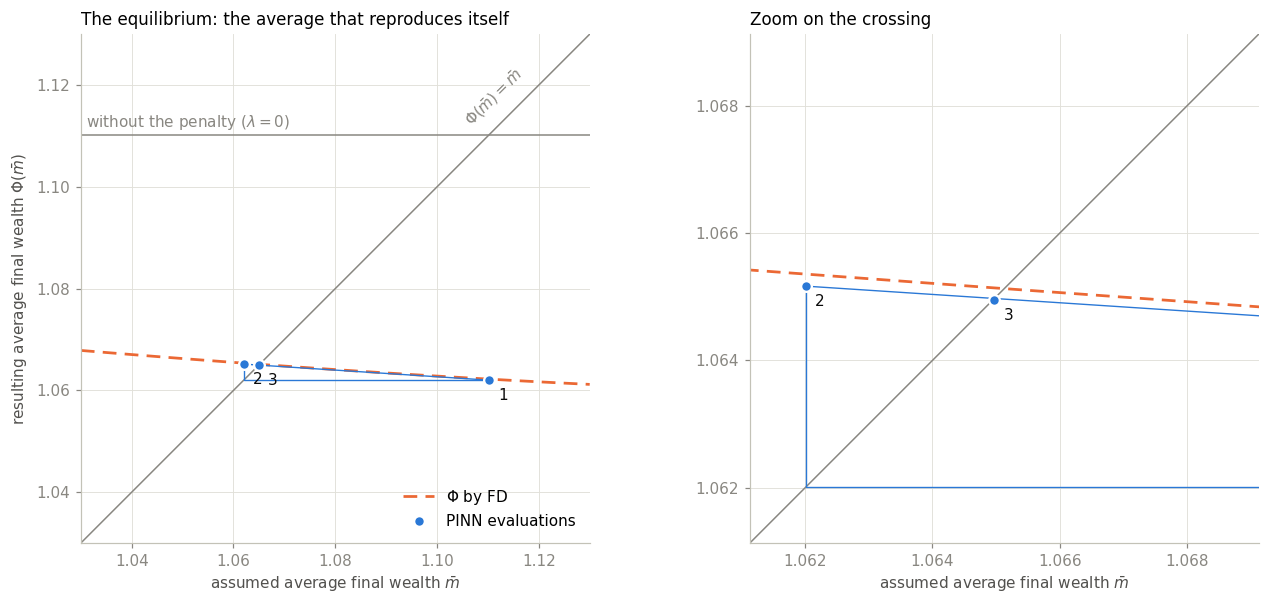

In [4]:
grid = np.linspace(1.03, 1.13, 21)
fd_curve = np.array([fd_phi(p, m) for m in grid])
m_k, phi_k = np.array(pinn_eq["history"]).T


def draw_search(ax):
    """FD curve, diagonal, the PINN's dots and the path of the search between them."""
    ax.plot(grid, grid, color=MUTED, lw=1.0)
    ax.plot(grid, fd_curve, color=FD, ls=FD_LINE, label=r"$\Phi$ by FD")
    # First step: plain iteration, across to the diagonal and down to the next dot.
    ax.plot([m_k[0], phi_k[0], m_k[1]], [phi_k[0], phi_k[0], phi_k[1]], color=PINN, lw=0.9)
    # Later steps: the line through the last two dots, to where it meets the diagonal, and from
    # there to the new dot.
    for k in range(2, len(m_k)):
        slope = (phi_k[k - 1] - phi_k[k - 2]) / (m_k[k - 1] - m_k[k - 2])
        ends = np.array([m_k[k - 2 : k + 1].min(), m_k[k - 2 : k + 1].max()])
        ax.plot(ends, phi_k[k - 1] + slope * (ends - m_k[k - 1]), color=PINN, lw=0.9)
        ax.plot([m_k[k], m_k[k]], [m_k[k], phi_k[k]], color=PINN, lw=0.9)
    ax.plot(m_k, phi_k, ls="none", color=PINN, label="PINN evaluations", zorder=3, **DOT)
    for k, (a, b) in enumerate(zip(m_k, phi_k), start=1):
        ax.annotate(str(k), (a, b), xytext=(6, -13), textcoords="offset points", color=INK)


fig, (ax, zoom) = plt.subplots(1, 2, figsize=(12.5, 5.6))
draw_search(ax)
ax.axhline(mbar_free, color=MUTED, lw=1.0)
ax.text(1.031, mbar_free + 0.0015, r"without the penalty ($\lambda = 0$)", color=MUTED)
ax.text(1.105, 1.112, r"$\Phi(\bar m) = \bar m$", color=MUTED, rotation=45)
ax.set(
    xlim=(1.03, 1.13),
    ylim=(1.03, 1.13),
    xlabel=r"assumed average final wealth $\bar m$",
    ylabel=r"resulting average final wealth $\Phi(\bar m)$",
    title="The equilibrium: the average that reproduces itself",
)
ax.legend(loc="lower right")
draw_search(zoom)
zoom.set(
    xlim=(mbar_fd - 0.004, mbar_fd + 0.004),
    ylim=(mbar_fd - 0.004, mbar_fd + 0.004),
    xlabel=r"assumed average final wealth $\bar m$",
    title="Zoom on the crossing",
)
zoom.locator_params(nbins=5)
for a in (ax, zoom):
    a.set_aspect("equal")
fig.tight_layout()
save(fig, "1_equilibrium_search")

**The answer.** Both methods find the same equilibrium. The tables give the numbers: the first
compares the methods, the second shows the PINN's evaluations one by one, each against FD's
$\Phi$ at the same $\bar m$.

In [5]:
show_table(
    ["", "equilibrium $\\bar m_T$", "evaluations of $\\Phi$", "time"],
    [
        ["without the penalty, $\\lambda = 0$ (exact)", f"{mbar_free:.6f}", "", ""],
        ["FD, 800 × 400 grid", f"{mbar_fd:.6f}", f"{len(fd_eq.history)}", f"{fd_seconds:.1f} s"],
        ["FD, 3200 × 1600 grid", f"{fd_fine.mbar:.6f}", f"{len(fd_fine.history)}", f"{fd_fine_seconds:.0f} s"],
        ["PINN", f"{mbar_pinn:.6f}", f"{len(m_k)}", f"{pinn_eq['seconds'] / 60:.0f} min"],
    ],
)
rows = []
for k, response in enumerate(pinn_eq["responses"], start=1):
    fd_value = fd_phi(p, response.mbar)
    start = "from scratch" if k == 1 else "from the previous networks"
    rows.append(
        [
            f"{k}",
            f"{response.mbar:.6f}",
            f"{response.phi:.6f}",
            f"{fd_value:.6f}",
            f"{response.phi - fd_value:+.1e}",
            f"{response.seconds / 60:.1f} min, {start}",
        ]
    )
show_table(
    ["PINN evaluation", "$\\bar m$ tried", "$\\Phi$, PINN", "$\\Phi$, FD", "PINN − FD", "training"],
    rows,
)

|  | equilibrium $\bar m_T$ | evaluations of $\Phi$ | time |
| --- | --- | --- | --- |
| without the penalty, $\lambda = 0$ (exact) | 1.110201 |  |  |
| FD, 800 × 400 grid | 1.065128 | 5 | 1.7 s |
| FD, 3200 × 1600 grid | 1.065126 | 5 | 10 s |
| PINN | 1.064973 | 3 | 11 min |

| PINN evaluation | $\bar m$ tried | $\Phi$, PINN | $\Phi$, FD | PINN − FD | training |
| --- | --- | --- | --- | --- | --- |
| 1 | 1.110201 | 1.062013 | 1.062217 | -2.0e-04 | 7.7 min, from scratch |
| 2 | 1.062013 | 1.065167 | 1.065355 | -1.9e-04 | 1.7 min, from the previous networks |
| 3 | 1.064973 | 1.064953 | 1.065140 | -1.9e-04 | 1.7 min, from the previous networks |

**What to look at.**

- **The penalty lowers the average.** Without it the average final wealth would be 1.110; with
  $\lambda = 2$ it is 1.065. Investors near the average take less risk so as not to fall below
  it, and so the population as a whole earns less.
- **The PINN lands within $1.5 \cdot 10^{-4}$ of FD,** after three evaluations. FD itself moves by
  only $2 \cdot 10^{-6}$ when its grid is made four times finer in each direction, so the gap is
  the PINN's error.
- **The PINN's $\Phi$ sits $2 \cdot 10^{-4}$ below FD's at all three points** (second table). A
  steady offset like this, rather than random noise, is what shifts the answer: since $\Phi$ is
  almost flat, the offset passes almost whole into $\bar m_T$.
- **The first evaluation is the slow one** (about 8 minutes, three networks trained from scratch).
  The next ones start from the networks before and take under 2 minutes each.

## 2. The strategy $\pi^*$ at the equilibrium

**What is plotted.** Four snapshots in time, $t = 0$, $0.5$, $0.9$ and $0.99$ (the horizon is
$T = 1$). In each, the horizontal axis is the investor's wealth $x$ and the vertical axis the
dollars they keep in the stock, $\pi^*(t, x)$, at the equilibrium.

- Solid blue: the PINN. Dashed orange: FD.
- Thin grey horizontal line: the Merton position, what everyone would hold without the penalty.
- Thin grey vertical line: the equilibrium average $\bar m_T$.
- Shaded band: where the middle 98% of the population is at that time (from the FD density).

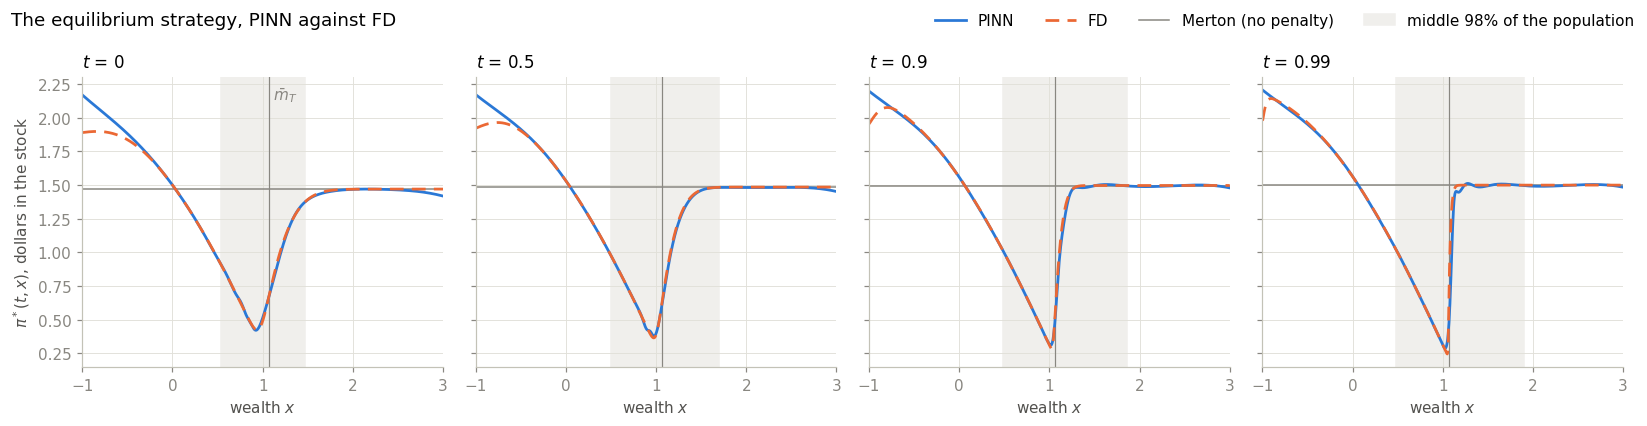

In [6]:
def population_range(t, share=0.98):
    """Wealth interval that holds the middle `share` of the FD population at time t."""
    x, dx = fd_eq.fp.x, fd_eq.fp.dx
    cdf = np.cumsum(fd_eq.fp.density(t, x)) * dx  # mass up to the right end of each cell
    tail = (1 - share) / 2
    return np.interp(tail, cdf, x + dx / 2), np.interp(1 - tail, cdf, x + dx / 2)


x = np.linspace(p.x_min, p.x_max, 801)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=True)
for ax, t in zip(axes, [0.0, 0.5, 0.9, 0.99]):
    ax.axvspan(*population_range(t), color=BAND, zorder=0)
    ax.axhline(merton_pi(t, p), color=MUTED, lw=1.0)
    ax.axvline(mbar_fd, color=MUTED, lw=0.8)
    ax.plot(x, pinn_final.value.position(t, x), color=PINN, label="PINN")
    ax.plot(x, fd_eq.hjb.position(t, x), color=FD, ls=FD_LINE, label="FD")
    ax.set(title=f"$t$ = {t:g}", xlabel="wealth $x$", xlim=(p.x_min, p.x_max))
axes[0].set_ylabel(r"$\pi^*(t, x)$, dollars in the stock")
axes[0].text(mbar_fd + 0.05, 0.92, r"$\bar m_T$", color=MUTED, transform=axes[0].get_xaxis_transform())
handles = [
    Line2D([], [], color=PINN, label="PINN"),
    Line2D([], [], color=FD, ls=FD_LINE, label="FD"),
    Line2D([], [], color=MUTED, lw=1.0, label="Merton (no penalty)"),
    Patch(color=BAND, label="middle 98% of the population"),
]
fig.legend(handles=handles, loc="upper right", ncol=4)
fig.suptitle("The equilibrium strategy, PINN against FD", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "2_strategy_slices")

**What to look at.**

- **Where the population lives (shaded), the PINN and FD lines lie on top of each other** at
  every time.
- **Far above the average,** investors hold the Merton position.
- **Just below the average,** they cut their position to about a third of Merton's: a loss would
  push them further below. Near the end the cut becomes a cliff right at $\bar m_T$. The PINN
  follows it, with a small ripple just above $\bar m_T$ at $t = 0.99$.
- **Far below the average,** they take more risk than Merton: they are already paying the
  penalty, and the stock is their chance to catch up. The curves cross the Merton line near
  $x = \bar m_T - 1/\gamma \approx 0.065$, a crossing that is exact at $t = T$.
- **The two methods part only near the lower edge $x = -1$,** where nobody lives. There the
  strategy is set by the edge condition, which both take from `benchmarks.py`; the network and
  the grid handle it differently, and the difference fades well before the population.

**What is plotted.** The same comparison over the whole domain at once: time $t$ on the
horizontal axis, wealth $x$ on the vertical axis.

- **Left, the value $V$:** the relative difference $(V_{\text{PINN}} - V_{\text{FD}}) / |V_{\text{FD}}|$, in percent.
- **Right, the strategy $\pi^*$:** the difference $\pi^*_{\text{PINN}} - \pi^*_{\text{FD}}$, in
  dollars. The colour scale stops at ±0.1; darker spots go beyond it.

Red means that the PINN is above FD, blue below, grey that they agree. The black curve encloses
where the population lives (FD density above 0.05), and the thin grey line is $\bar m_T$.

V:   largest gap 0.48% of |V| anywhere, 0.21% for 0 <= x <= 2.2
pi*: largest gap for 0 <= x <= 2.2: 0.067 dollars for t <= 0.9, 0.89 dollars for all t


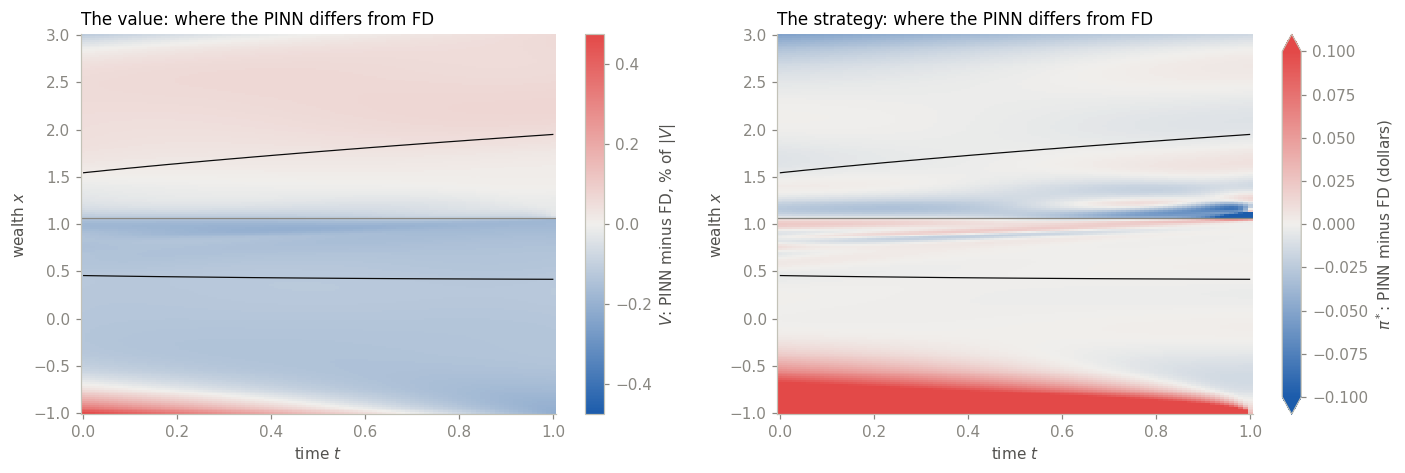

In [7]:
tt, xx = np.meshgrid(np.linspace(0.0, p.T, 101), np.linspace(p.x_min, p.x_max, 201))
value_gap = (pinn_final.value.value(tt, xx) - fd_eq.hjb.value(tt, xx)) / np.abs(fd_eq.hjb.value(tt, xx))
position_gap = pinn_final.value.position(tt, xx) - fd_eq.hjb.position(tt, xx)
lives = fd_eq.fp.density(tt, xx)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
panels = [
    (axes[0], 100 * value_gap, np.abs(100 * value_gap).max(), "neither", "$V$: PINN minus FD, % of $|V|$", "value"),
    (axes[1], position_gap, 0.1, "both", r"$\pi^*$: PINN minus FD (dollars)", "strategy"),
]
for ax, gap, limit, extend, label, name in panels:
    mesh = ax.pcolormesh(tt, xx, gap, cmap=LESS_MORE, norm=Normalize(-limit, limit), shading="auto")
    ax.contour(tt, xx, lives, levels=[0.05], colors=INK, linewidths=0.8)
    ax.axhline(mbar_fd, color=MUTED, lw=0.8)
    fig.colorbar(mesh, ax=ax, label=label, extend=extend)
    ax.set(xlabel="time $t$", ylabel="wealth $x$", title=f"The {name}: where the PINN differs from FD")
    ax.grid(False)
fig.tight_layout()
save(fig, "2_difference_maps")

people = (xx >= 0.0) & (xx <= 2.2)  # where the population lives, as in sections 4 and 7
print(f"V:   largest gap {np.abs(100 * value_gap).max():.2f}% of |V| anywhere, "
      f"{np.abs(100 * value_gap[people]).max():.2f}% for 0 <= x <= 2.2")
print(f"pi*: largest gap for 0 <= x <= 2.2: {np.abs(position_gap[people & (tt <= 0.9)]).max():.3f} "
      f"dollars for t <= 0.9, {np.abs(position_gap[people]).max():.2f} dollars for all t")

**What to look at.**

- **The value** agrees within half a percent everywhere, and within a fifth of a percent where
  the population lives (printed above).
- **The strategy** agrees within a few cents inside the black curve, except in one spot: just
  above $\bar m_T$ in the last tenth of the horizon (dark blue). There $\pi^*$ jumps from about
  0.2 to 1.5 dollars across a very narrow range of wealth (see $t = 0.99$ above), and a smooth
  network rounds the jump off.
- **A small error in $V$ does not mean a small error in $\pi^*$.** The strategy depends on the
  curvature of $V$, which magnifies errors; this is why the value network is also told the
  slopes of $v$ at $t = T$ (section 5).
- Below the black curve, the large differences near $x = -1$ come from the edge, as in the
  slices above.

## 3. The wealth distribution $m$ at the equilibrium

**What is plotted.** The density of the population's wealth, $m(t, x)$: how many investors have
wealth $x$ at time $t$ (the area under each curve is 1). Three snapshots, $t = 0.5$, $0.9$ and
$1$, and on the right a zoom of $t = 1$ around the average.

- Solid blue: the PINN. Dashed orange: FD.
- Thin grey curve: the population without the penalty (exact: a bell curve, since everyone
  holds the Merton position).
- Thin grey vertical line: the equilibrium average $\bar m_T$.

highest density at t = 1: 4.3 by FD, 3.5 by the PINN
total mass at t = 1: 1 by FD (exactly), 0.9984 by the PINN


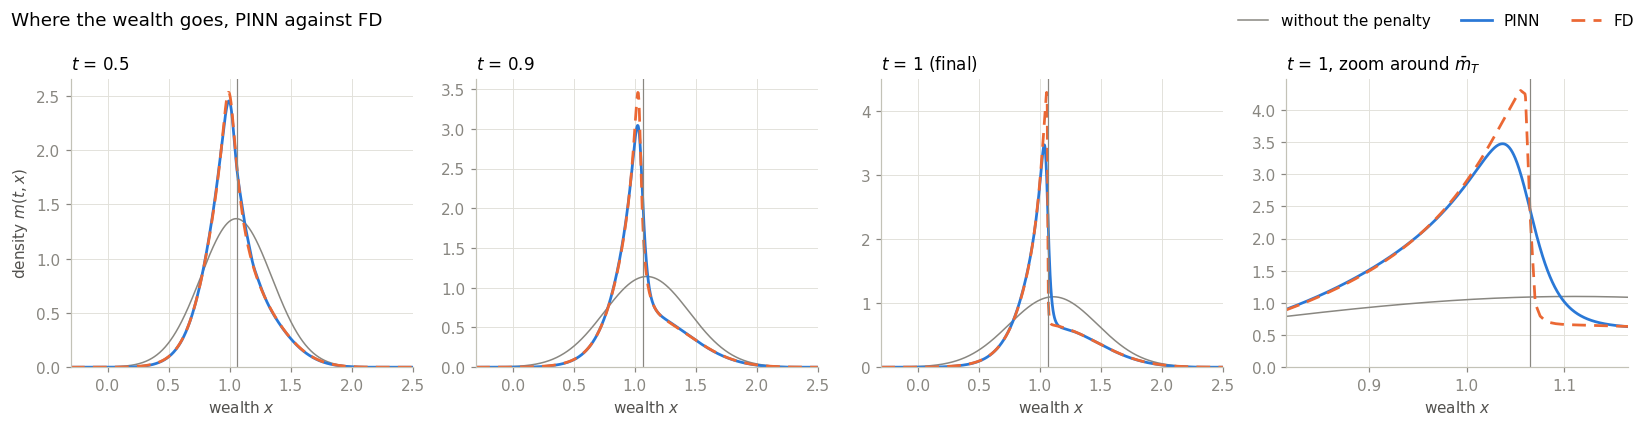

In [8]:
def free_density(t, x):
    """The density without the penalty: Gaussian with the exact mean and variance."""
    var = population_var(t, p)
    return np.exp(-((x - population_mean(t, p)) ** 2) / (2 * var)) / np.sqrt(2 * np.pi * var)


x = np.linspace(-0.3, 2.5, 1401)
x_zoom = np.linspace(mbar_fd - 0.25, mbar_fd + 0.1, 701)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
snapshots = [(0.5, x, "$t$ = 0.5"), (0.9, x, "$t$ = 0.9"), (1.0, x, "$t$ = 1 (final)"),
             (1.0, x_zoom, r"$t$ = 1, zoom around $\bar m_T$")]
for ax, (t, xs, title) in zip(axes, snapshots):
    ax.plot(xs, free_density(t, xs), color=MUTED, lw=1.0, label=r"without the penalty")
    ax.plot(xs, pinn_final.density.density(t, xs), color=PINN, label="PINN")
    ax.plot(xs, fd_eq.fp.density(t, xs), color=FD, ls=FD_LINE, label="FD")
    ax.axvline(mbar_fd, color=MUTED, lw=0.8)
    ax.set(title=title, xlabel="wealth $x$", xlim=(xs[0], xs[-1]), ylim=(0, None))
axes[0].set_ylabel("density $m(t, x)$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=3)
fig.suptitle("Where the wealth goes, PINN against FD", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "3_density_snapshots")
print(f"highest density at t = 1: {fd_eq.fp.density(1.0, x_zoom).max():.1f} by FD, "
      f"{pinn_final.density.density(1.0, x_zoom).max():.1f} by the PINN")
print(f"total mass at t = 1: 1 by FD (exactly), {pinn_final.density.mass(1.0):.4f} by the PINN")

**What to look at.**

- **The penalty squeezes the population against the average.** Compared with the bell curve
  without the penalty, fewer investors end far from the average, and many crowd just below it:
  they are the ones who cut their position to avoid falling under it.
- **At the end the crowd stops at a cliff right at $\bar m_T$.** Just below the average investors
  hold little stock (about 0.2 dollars), so their wealth hardly moves; just above it they hold
  the Merton position and spread out. So the density drops from about 4.3 to 0.7 within about a
  hundredth of a dollar.
- **The PINN follows FD closely until about $t = 0.9$,** then rounds the cliff off: its peak is
  lower, and part of the crowd ends just above the average instead of just below. Its total mass
  at the end is 0.998 instead of 1 (printed above). The average, which is what the equilibrium
  needs, is hardly affected (section 1).

## 4. How fast each method converges

### Accuracy against computing time

Here both methods solve only the HJB, for a fixed assumed average $\bar m = 1.1$ (the common test
case of `CONTRIBUTING.md`), and we measure how good their strategy $\pi^*$ is for the time spent.

- **FD** is run on finer and finer grids: from 25 to 3200 steps in wealth (and half as many in time).
- **The PINN** is trained from scratch with more and more Adam steps, from 500 to 20 000, each
  followed by the usual 500 L-BFGS steps.

The error is the largest gap in $\pi^*$ where the population lives ($0 \le x \le 2.2$) and for
$t \le 0.9$. The last tenth of the horizon is left out because there $\pi^*$ jumps at $\bar m$
(section 2), and that single spot would hide everything else. The reference is

- the exact Merton position without the penalty ($\lambda = 0$),
- FD on a 6400 × 3200 grid with the penalty ($\lambda = 2$).

FD runs on the CPU, the PINN on the GPU.

In [9]:
GRIDS = [25, 50, 100, 200, 400, 800, 1600, 3200]  # FD: steps in wealth (half as many in time)
BUDGETS = [500, 1000, 2000, 5000, 10_000, 20_000]  # PINN: Adam steps before L-BFGS
t_box, x_box = np.meshgrid(np.linspace(0.0, 0.9, 46), np.linspace(0.0, 2.2, 111), indexing="ij")


def value_nets_by_budget(q):
    """Value networks trained from scratch with each Adam budget, with their training times."""
    return [timed(lambda: train_value_net(q, 1.1, ValueNetSettings(adam_steps=n))) for n in BUDGETS]


accuracy = {}
for lam in (0.0, 2.0):
    q = p.with_(lam=lam)
    if lam == 0.0:
        reference = merton_pi(t_box, q) + 0 * x_box
    else:
        reference = solve_hjb(q, 1.1, 6400, 3200).position(t_box, x_box)
    fd_runs = [timed(lambda: solve_hjb(q, 1.1, nx, nx // 2)) for nx in GRIDS]
    pinn_runs = cached(f"value_nets_by_budget_lam{lam:g}", lambda: value_nets_by_budget(q))
    accuracy[lam] = {
        method: (
            [seconds for _, seconds in runs],
            [np.abs(sol.position(t_box, x_box) - reference).max() for sol, _ in runs],
        )
        for method, runs in (("FD", fd_runs), ("PINN", pinn_runs))
    }

**What is plotted.** One panel without the penalty and one with it. The horizontal axis is the
computing time in seconds, the vertical axis the largest error of $\pi^*$ (in dollars), both on
log scales: each gridline is ten times the one before.

- Dashed orange: FD, one dot per grid, labelled with its number of steps in wealth.
- Solid blue: the PINN, one dot per training length, labelled with its number of Adam steps.

| $\lambda$ | method | grid steps / Adam steps | seconds | largest $\pi^*$ error |
| --- | --- | --- | --- | --- |
| 0 | FD | 25 | 0.01 | 3.3e-03 |
| 0 | FD | 50 | 0.02 | 8.8e-04 |
| 0 | FD | 100 | 0.03 | 2.5e-04 |
| 0 | FD | 200 | 0.05 | 7.9e-05 |
| 0 | FD | 400 | 0.10 | 2.8e-05 |
| 0 | FD | 800 | 0.22 | 1.1e-05 |
| 0 | FD | 1,600 | 0.52 | 4.7e-06 |
| 0 | FD | 3,200 | 1.27 | 2.2e-06 |
| 0 | PINN | 500 | 24.80 | 4.4e-03 |
| 0 | PINN | 1,000 | 27.21 | 3.2e-03 |
| 0 | PINN | 2,000 | 31.01 | 4.4e-03 |
| 0 | PINN | 5,000 | 67.44 | 1.2e-02 |
| 0 | PINN | 10,000 | 124.79 | 1.1e-02 |
| 0 | PINN | 20,000 | 248.61 | 2.7e-03 |
| 2 | FD | 25 | 0.01 | 2.1e-01 |
| 2 | FD | 50 | 0.02 | 9.0e-02 |
| 2 | FD | 100 | 0.03 | 4.4e-02 |
| 2 | FD | 200 | 0.06 | 1.4e-02 |
| 2 | FD | 400 | 0.13 | 5.5e-03 |
| 2 | FD | 800 | 0.25 | 2.2e-03 |
| 2 | FD | 1,600 | 0.52 | 9.4e-04 |
| 2 | FD | 3,200 | 1.28 | 3.2e-04 |
| 2 | PINN | 500 | 24.42 | 1.8e-01 |
| 2 | PINN | 1,000 | 30.82 | 2.1e-01 |
| 2 | PINN | 2,000 | 43.17 | 1.5e-01 |
| 2 | PINN | 5,000 | 80.43 | 9.4e-02 |
| 2 | PINN | 10,000 | 143.23 | 8.8e-02 |
| 2 | PINN | 20,000 | 266.58 | 6.9e-02 |

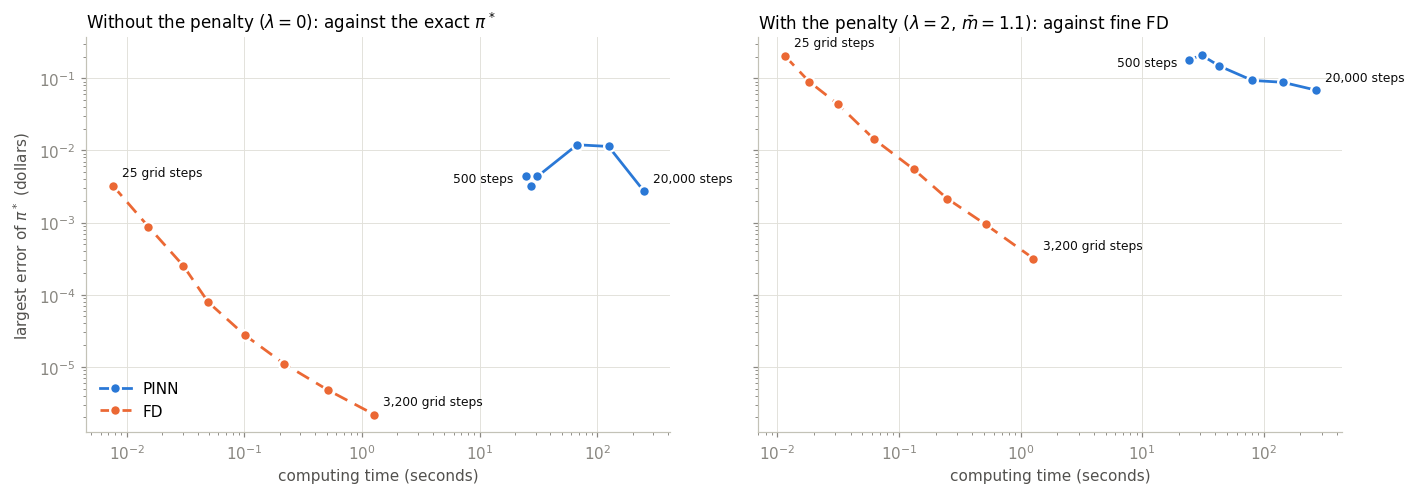

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
titles = {0.0: r"Without the penalty ($\lambda = 0$): against the exact $\pi^*$",
          2.0: r"With the penalty ($\lambda = 2$, $\bar m = 1.1$): against fine FD"}
for ax, lam in zip(axes, (0.0, 2.0)):
    for method, colour, style, labels in (("PINN", PINN, "-", BUDGETS), ("FD", FD, FD_LINE, GRIDS)):
        seconds, errors = accuracy[lam][method]
        ax.loglog(seconds, errors, color=colour, ls=style, label=method, **DOT)
        for i in (0, len(labels) - 1):  # label the first and last dot of each line
            text = f"{labels[i]:,} steps" if method == "PINN" else f"{labels[i]:,} grid steps"
            # The PINN's first label goes to the left, clear of the dots right after it.
            left = method == "PINN" and i == 0
            ax.annotate(text, (seconds[i], errors[i]), xytext=(-8, -4) if left else (6, 6),
                        textcoords="offset points", ha="right" if left else "left",
                        color=INK, fontsize=8)
    ax.set(title=titles[lam], xlabel="computing time (seconds)")
axes[0].set_ylabel(r"largest error of $\pi^*$ (dollars)")
axes[0].legend(loc="lower left")
fig.tight_layout()
save(fig, "4_accuracy_vs_time")

rows = []
for lam in (0.0, 2.0):
    for method, labels in (("FD", GRIDS), ("PINN", BUDGETS)):
        seconds, errors = accuracy[lam][method]
        for label, s, e in zip(labels, seconds, errors):
            rows.append([f"{lam:g}", method, f"{label:,}", f"{s:.2f}", f"{e:.1e}"])
show_table(["$\\lambda$", "method", "grid steps / Adam steps", "seconds", "largest $\\pi^*$ error"], rows)

**What to look at.**

- **FD improves steadily as its grid gets finer:** each doubling of the grid divides the error by
  2 to 4. Without the penalty it reaches $2 \cdot 10^{-6}$ dollars in about a second.
- **The PINN does not improve steadily with longer training.** Without the penalty its error
  stays between 0.003 and 0.012 dollars whatever the number of steps: it depends more on where
  each training happens to end than on how long it runs (the final losses in the table above
  jump around in the same way). With the penalty it falls slowly, from 0.2 to 0.07 dollars,
  always worst at the same spot: just above $\bar m$ at $t = 0.9$, where the jump of $\pi^*$
  begins to form.
- **At equal accuracy FD is about ten thousand times faster here.** With the penalty, 20 000
  PINN steps (4.5 minutes) reach the accuracy of a 50- to 100-step FD grid (a few hundredths of
  a second).
- **This is expected in one dimension.** A grid needs $n^d$ points for $d$ state variables, so
  its cost explodes as $d$ grows; a PINN samples random points, and its cost grows far more
  slowly. PINNs pay off for richer versions of the game, where a grid is out of reach. Here the
  one-dimensional problem lets FD check them.

### The search for the equilibrium

**What is plotted.** How quickly each search of section 1 closes the gap. The horizontal axis is
the evaluation number $k$; the vertical axis the gap $|\Phi(\bar m_k) - \bar m_k|$ at the
$\bar m_k$ tried, on a log scale (each line is ten times smaller than the one above).

- Dashed orange: FD. Solid blue: the PINN.
- The thin grey line is the PINN's stopping tolerance, $2 \cdot 10^{-4}$. Its $\Phi$ carries
  training noise of about that size, so asking for less would not help. FD stops at $10^{-10}$.

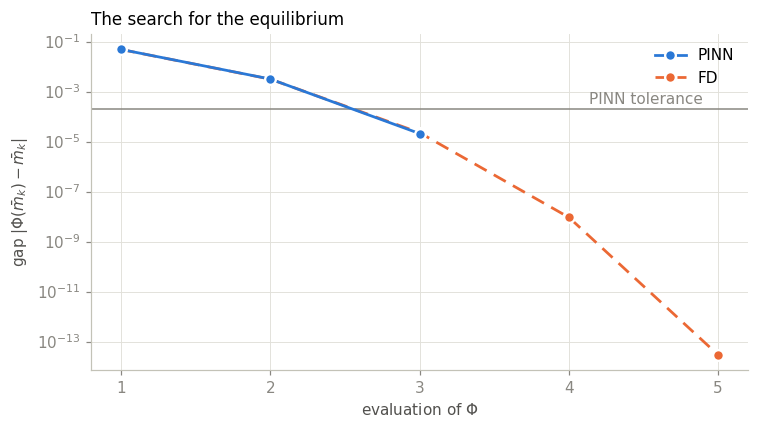

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.0))
for method, history, colour, style in (("PINN", pinn_eq["history"], PINN, "-"),
                                       ("FD", fd_eq.history, FD, FD_LINE)):
    gaps = [abs(phi - m) for m, phi in history]
    # The PINN is drawn on top: its first dots coincide with FD's.
    ax.semilogy(range(1, len(gaps) + 1), gaps, color=colour, ls=style, label=method,
                zorder=3 if method == "PINN" else 2, **DOT)
tolerance = PinnEquilibriumSettings().tol
ax.axhline(tolerance, color=MUTED, lw=1.0)
ax.text(4.9, tolerance * 1.6, "PINN tolerance", color=MUTED, ha="right")
ax.set(xlabel="evaluation of $\\Phi$", ylabel=r"gap $|\Phi(\bar m_k) - \bar m_k|$",
       title="The search for the equilibrium", xticks=range(1, 6))
ax.legend()
fig.tight_layout()
save(fig, "4_equilibrium_search_gap")

**What to look at.**

- **The two searches take the same steps.** Their $\Phi$ values differ by only $2 \cdot 10^{-4}$,
  so the PINN's dots hide FD's.
- **The secant method closes the gap fast:** from $5 \cdot 10^{-2}$ to $3 \cdot 10^{-3}$,
  $2 \cdot 10^{-5}$, $10^{-8}$ and $3 \cdot 10^{-14}$ for FD. Each evaluation multiplies the number
  of correct digits by 1.7 to 1.9, as expected of the secant method.
- **The PINN stops after three evaluations,** once below its tolerance; going further would only
  chase its training noise.

## 5. What each part of the loss does

Each PINN is trained by making its loss small: a sum of parts, each the mean of a squared error
over random points (drawn again at every Adam step), all with coefficient 1. The plots use the
first evaluation of section 1, the one trained from scratch, at $\bar m = 1.110$. Here
$v_{\theta_V} = \log(-V)$ is the value network and $q_{\theta_m} = \log m$ the density network,
with weights $\theta_V$ and $\theta_m$.

| network | part | what it measures | points per step |
| --- | --- | --- | --- |
| value, $L_V$ | equation | the HJB residual of $v_{\theta_V}$, divided by $\kappa^2/2$ | 5000 inside |
| | terminal | $v_{\theta_V}(T, x) - \log(-U(x, \bar m))$: the final value | 1000 at $t = T$ |
| | slopes | $\partial_x v_{\theta_V}$ and $\partial_{xx} v_{\theta_V}$ minus their exact values at $t = T$, except within 0.05 of $\bar m$ | the same 1000 |
| | edges | $v_{\theta_V}$ minus the edge values shared with FD, at $x = -1$ and $x = 3$ | 2 × 200 |
| density, $L_m$ | equation | the Fokker–Planck residual $\partial_t m + \partial_x(b\,m) - \frac12 \partial_{xx}(s^2 m)$ | 6000 inside |
| | mass | $\int m\,dx - 1$, the total mass minus one | 16 times |

The value network's parts are written out in full in `pinn_value_net_example.ipynb`, and both
losses in the docstrings of `src/mfg/pinn/hjb.py` and `src/mfg/pinn/fokker_planck.py`. The
density network needs no loss for the start, $m(0, x) = m_0(x)$, because its form
$q_{\theta_m} = \log m_0 + t\,\psi_{\theta_m}$ holds it exactly.

**What is plotted.** Left the value network, right the density network. The horizontal axis is
the training step: 10 000 Adam steps, then L-BFGS (shaded), whose result is the last dot.

- **Top:** each part of the loss, on a log scale.
- **Bottom:** the share of the total loss that each part makes up, in percent (the coloured bands
  stack up to 100%).

| network | part | at the start | at the end | share at the end |
| --- | --- | --- | --- | --- |
| Value network | equation | 5.3e+01 | 1.6e-04 | 78% |
| Value network | terminal | 3.4e+00 | 1.6e-06 | 1% |
| Value network | slopes | 2.9e+00 | 4.0e-05 | 19% |
| Value network | edges | 7.7e+00 | 3.7e-06 | 2% |
| Density network | equation | 7.3e-01 | 6.0e-04 | 100% |
| Density network | mass | 4.6e-03 | 2.0e-06 | 0% |

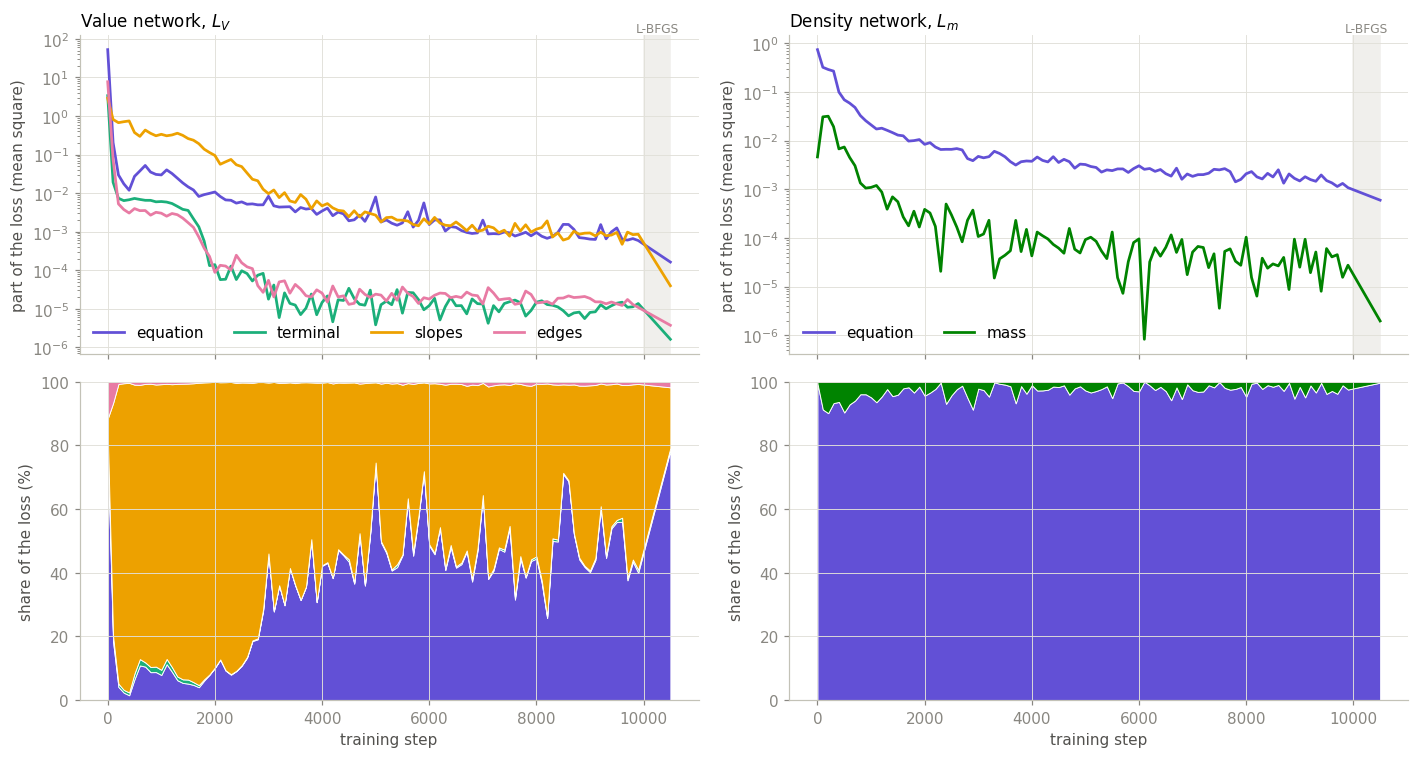

In [12]:
first = pinn_eq["responses"][0]
networks = [
    ("Value network, $L_V$", first.value.history, ["equation", "terminal", "slopes", "edges"]),
    ("Density network, $L_m$", first.density.history, ["equation", "mass"]),
]
adam_steps = PinnEquilibriumSettings().first.value.adam_steps

fig, axes = plt.subplots(2, 2, figsize=(13, 7.0), sharex=True)
for col, (title, history, parts) in enumerate(networks):
    steps, total = np.array(history["step"]), np.array(history["total"])
    top, bottom = axes[0, col], axes[1, col]
    for name in parts:
        top.semilogy(steps, history[name], color=LOSS_COLOURS[name], label=name)
    top.set(title=title, ylabel="part of the loss (mean square)")
    top.legend(loc="lower left", ncol=len(parts))
    shares = 100 * np.array([history[name] for name in parts]) / total
    bottom.stackplot(steps, shares, colors=[LOSS_COLOURS[n] for n in parts], edgecolor="white",
                     linewidth=0.6)
    bottom.set(ylim=(0, 100), xlabel="training step", ylabel="share of the loss (%)")
    for ax in (top, bottom):
        ax.axvspan(adam_steps, steps[-1], color=BAND, zorder=0)
    top.text(0.5 * (adam_steps + steps[-1]), 1.0, "L-BFGS", color=MUTED, ha="center",
             va="bottom", fontsize=8, transform=top.get_xaxis_transform())
fig.tight_layout()
save(fig, "5_loss_parts")

rows = []
for title, history, parts in networks:
    for name in parts:
        rows.append([title.split(",")[0], name, f"{history[name][0]:.1e}", f"{history[name][-1]:.1e}",
                     f"{100 * history[name][-1] / history['total'][-1]:.0f}%"])
show_table(["network", "part", "at the start", "at the end", "share at the end"], rows)

**What to look at.**

- **The value network learns its conditions first and the equation later.** The final value and
  the edges (green and pink) fall below $10^{-4}$ within 2000 steps and stay there, a few percent
  of the loss at most. The rest of the training goes into the equation and the final slopes.
- **The final slopes are the hardest part for most of the training** (yellow: about 90% of the
  loss until step 2500). They pin down the curvature of $v$ at $T$, next to the kink at
  $\bar m$, and the curvature is what sets $\pi^*$. L-BFGS divides them by 20 in its 500 steps,
  and at the end the equation makes up most of the loss.
- **The density network's loss is almost all equation.** The mass part stays far below it, at
  $10^{-6}$ to $10^{-4}$. Since the start is exact and the equation nearly holds, the total mass
  stays close to 1 almost by itself; this part only stops it from drifting.
- The spikes come from the random points, which are drawn again at every step.

## 6. The strength of the penalty $\lambda$

So far $\lambda = 2$. Here the equilibrium is computed with FD for penalty strengths from 0 (no
penalty) to 10, which takes about two seconds each. The PINN has only been run at $\lambda = 2$;
it is the blue dot.

In [13]:
LAMBDAS = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.5, 10.0]
sweep = {lam: solve_equilibrium(p.with_(lam=lam)) for lam in LAMBDAS}


def final_wealth_stats(x, m, mbar):
    """Mean, standard deviation and share below mbar of the final density m on the points x."""
    mass = np.trapezoid(m, x)
    mean = np.trapezoid(x * m, x) / mass
    spread = np.sqrt(np.trapezoid((x - mean) ** 2 * m, x) / mass)
    # Share below mbar from the running integral, read exactly at mbar (the density jumps there).
    running = np.concatenate([[0.0], np.cumsum(0.5 * (m[1:] + m[:-1]) * np.diff(x))]) / mass
    return mean, spread, np.interp(mbar, x, running)


fd_stats = np.array([final_wealth_stats(sweep[lam].fp.x, sweep[lam].fp.m[-1], sweep[lam].mbar)
                     for lam in LAMBDAS])
x_fine = np.linspace(p.x_min, p.x_max, 4001)
pinn_stats = final_wealth_stats(x_fine, pinn_final.density.density(1.0, x_fine), mbar_pinn)

**What is plotted.** Three numbers that describe the population at the end, against the
penalty strength $\lambda$ on the horizontal axis:

- **left,** the equilibrium average $\bar m_T$;
- **centre,** the spread of final wealth (its standard deviation);
- **right,** the share of investors who end below the average.

Dashed orange with dots: FD at each $\lambda$ computed. Blue dot: the PINN at $\lambda = 2$.
Thin grey line: the value without the penalty.

| $\lambda$ | $\bar m_T$ | spread | share below $\bar m_T$ |
| --- | --- | --- | --- |
| 0 | 1.1102 | 0.363 | 50% |
| 0.25 | 1.0944 | 0.327 | 56% |
| 0.5 | 1.0850 | 0.308 | 59% |
| 1 | 1.0744 | 0.290 | 64% |
| 1.5 | 1.0687 | 0.282 | 66% |
| 2 | 1.0651 | 0.278 | 67% |
| 3 | 1.0610 | 0.273 | 69% |
| 4 | 1.0587 | 0.270 | 69% |
| 5 | 1.0572 | 0.269 | 70% |
| 7.5 | 1.0551 | 0.267 | 70% |
| 10 | 1.0540 | 0.266 | 70% |
| 2 (PINN) | 1.0649 | 0.271 | 64% |

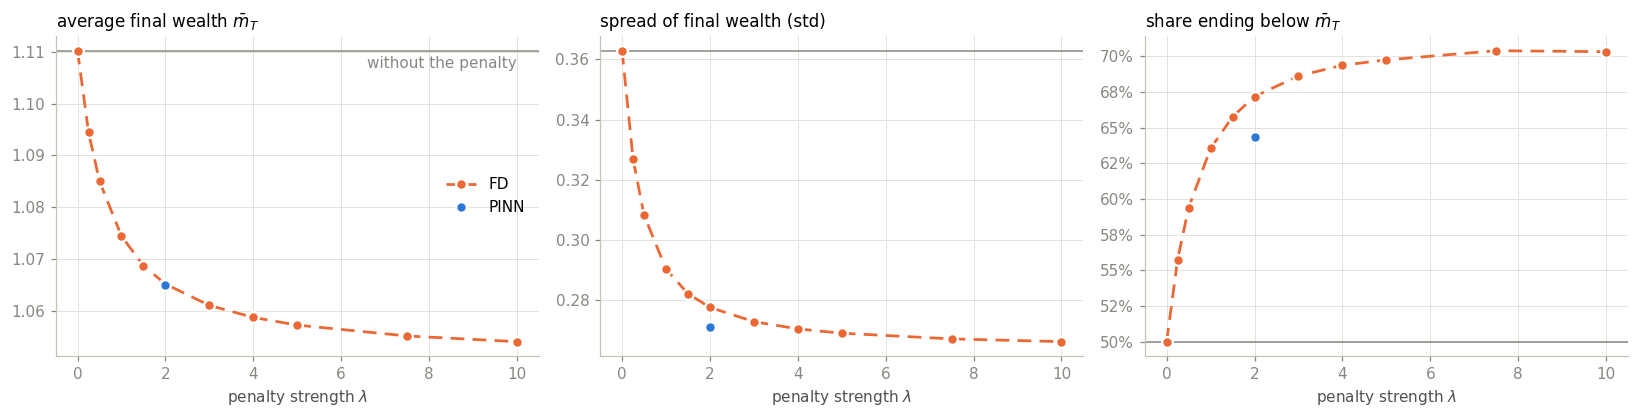

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
names = [r"average final wealth $\bar m_T$", "spread of final wealth (std)", r"share ending below $\bar m_T$"]
for i, (ax, name) in enumerate(zip(axes, names)):
    values = fd_stats[:, i]
    ax.axhline(values[0], color=MUTED, lw=1.0)
    ax.plot(LAMBDAS, values, color=FD, ls=FD_LINE, label="FD", **DOT)
    ax.plot([p.lam], [pinn_stats[i]], ls="none", color=PINN, label="PINN", zorder=3, **DOT)
    ax.set(title=name, xlabel=r"penalty strength $\lambda$")
axes[0].text(10, fd_stats[0, 0] - 0.001, "without the penalty", color=MUTED, ha="right", va="top")
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{100 * y:.0f}%"))
axes[0].legend(loc="center right")
fig.tight_layout()
save(fig, "6_penalty_numbers")

show_table(
    ["$\\lambda$", "$\\bar m_T$", "spread", "share below $\\bar m_T$"],
    [[f"{lam:g}", f"{s[0]:.4f}", f"{s[1]:.3f}", f"{100 * s[2]:.0f}%"] for lam, s in zip(LAMBDAS, fd_stats)]
    + [["2 (PINN)", f"{pinn_stats[0]:.4f}", f"{pinn_stats[1]:.3f}", f"{100 * pinn_stats[2]:.0f}%"]],
)

**What to look at.**

- **Competing costs money.** The average final wealth falls from 1.110 to 1.054 as $\lambda$
  grows: to avoid ending below the others, investors hold less stock and earn less of its
  premium. Most of the fall happens by $\lambda = 2$.
- **Wealth becomes more equal.** The spread falls from 0.36 to 0.27.
- **Yet more investors end below the average: 70% instead of 50%.** The penalty does not keep
  people from ending below the average; it makes them end only just below it. The crowd that
  piles up under $\bar m_T$ (section 3) tips the share.
- **The PINN at $\lambda = 2$ agrees on the average, but not quite on the other two** (last row
  of the table). Its density has thinner tails than FD's, because its loss gives little weight
  to places with few investors, so its spread is smaller. It also rounds the cliff off, so part
  of the crowd ends just above the average instead of just below, and the share below drops by
  a few points: about 4% of the investors sit within 0.01 below $\bar m_T$.

**What is plotted.** The FD equilibrium for five penalty strengths: $\lambda = 0$ (thin grey) and
$\lambda = 1, 2, 5, 10$ (dashed, from light to dark orange as the penalty grows).

- **Left:** the strategy at the start, $\pi^*(0, x)$, against wealth $x$.
- **Right:** the final density $m(T, x)$, against wealth $x$.

Each $\lambda$ has its own equilibrium average; they all lie between 1.05 and 1.08, except
1.11 without the penalty.

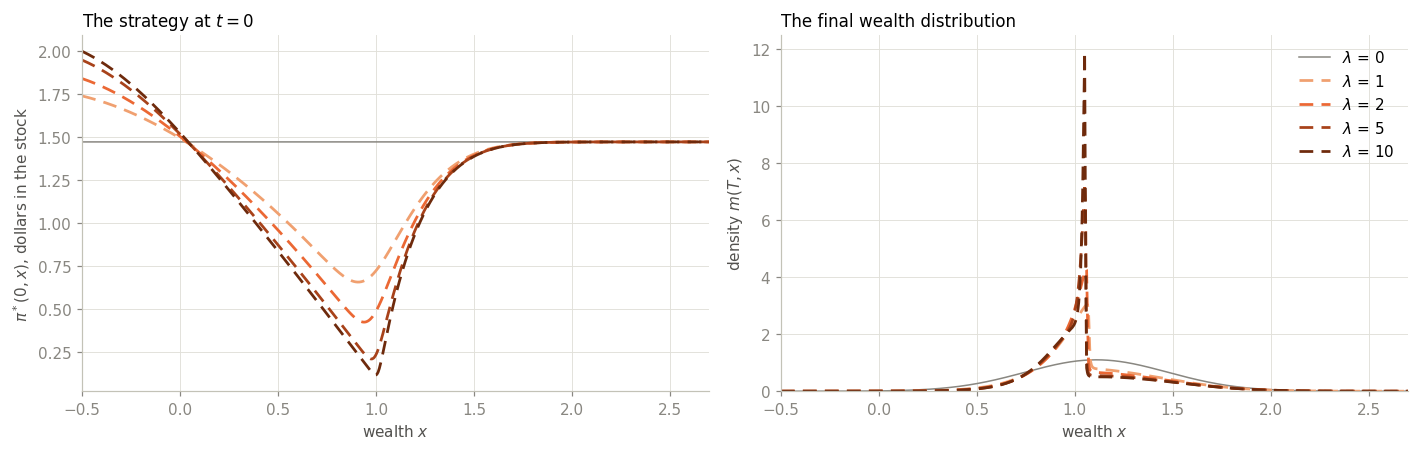

In [15]:
x = np.linspace(-0.5, 2.7, 1601)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, read in zip(axes, ("position", "density")):
    for lam, colour in zip([0.0, 1.0, 2.0, 5.0, 10.0], [MUTED, *LAMBDA_RAMP]):
        eq = sweep[lam]
        y = eq.hjb.position(0.0, x) if read == "position" else eq.fp.density(p.T, x)
        style = {"lw": 1.0} if lam == 0 else {"ls": FD_LINE}
        ax.plot(x, y, color=colour, label=rf"$\lambda$ = {lam:g}", **style)
    ax.set(xlabel="wealth $x$", xlim=(x[0], x[-1]))
axes[0].set(title=r"The strategy at $t = 0$", ylabel=r"$\pi^*(0, x)$, dollars in the stock")
axes[1].set(title=r"The final wealth distribution", ylabel="density $m(T, x)$", ylim=(0, None))
axes[1].legend(loc="upper right")
fig.tight_layout()
save(fig, "6_penalty_curves")

**What to look at.**

- **Left:** the stronger the penalty, the deeper the cut just below the average (down to about
  0.1 dollars at $\lambda = 10$), and the more risk taken far below it. All the curves cross
  Merton close to $x = \bar m_T - 1/\gamma$, between 0.05 and 0.07 depending on $\lambda$. Far
  above the average, $\lambda$ makes no difference.
- **Right:** the stronger the penalty, the taller and thinner the crowd just below the average.
  Its peak grows from about 3 at $\lambda = 1$ to about 12 at $\lambda = 10$.

## 7. Summary

The two methods against each other at $\lambda = 2$. The reference for the errors is FD on the
3200 × 1600 grid; the $\pi^*$ error is the largest gap where the population lives
($0 \le x \le 2.2$, $t \le 0.9$), as in section 4.

In [16]:
t_ref, x_ref = np.meshgrid(np.linspace(0.0, 0.9, 46), np.linspace(0.0, 2.2, 111), indexing="ij")
reference_pi = fd_fine.hjb.position(t_ref, x_ref)
tt, xx = np.meshgrid(np.linspace(0.0, p.T, 101), np.linspace(p.x_min, p.x_max, 201))
reference_v = fd_fine.hjb.value(tt, xx)


def summary(mbar, solution, seconds):
    """Error of the equilibrium mean, of pi* where people live, of V anywhere, and the time."""
    pi_error = np.abs(solution.position(t_ref, x_ref) - reference_pi).max()
    v_error = np.abs(solution.value(tt, xx) / reference_v - 1).max()
    return [f"{mbar - fd_fine.mbar:+.1e}", f"{pi_error:.1e}", f"{100 * v_error:.3f}%", seconds]


weights = sum(w.numel() for w in pinn_final.value.net.parameters())
cold, warm = pinn_eq["responses"][0].seconds, pinn_eq["responses"][-1].seconds
show_table(
    ["", "FD, 800 × 400 grid", "PINN"],
    [
        ["equilibrium $\\bar m_T$", f"{mbar_fd:.6f}", f"{mbar_pinn:.6f}"],
        *[
            [label, a, b]
            for label, a, b in zip(
                ["error of $\\bar m_T$", "largest error of $\\pi^*$ (dollars)",
                 "largest relative error of $V$", "time for the equilibrium"],
                summary(mbar_fd, fd_eq.hjb, f"{fd_seconds:.1f} s"),
                summary(mbar_pinn, pinn_final.value, f"{pinn_eq['seconds'] / 60:.0f} min"),
            )
        ],
        ["one evaluation of $\\Phi$", f"{fd_seconds / len(fd_eq.history):.2f} s",
         f"{cold / 60:.1f} min from scratch, {warm / 60:.1f} min after"],
        ["what the solution is", "values on 801 × 401 grid points",
         f"3 networks of {weights:,} weights each"],
    ],
)

|  | FD, 800 × 400 grid | PINN |
| --- | --- | --- |
| equilibrium $\bar m_T$ | 1.065128 | 1.064973 |
| error of $\bar m_T$ | +2.2e-06 | -1.5e-04 |
| largest error of $\pi^*$ (dollars) | 1.8e-03 | 6.6e-02 |
| largest relative error of $V$ | 0.001% | 0.476% |
| time for the equilibrium | 1.7 s | 11 min |
| one evaluation of $\Phi$ | 0.34 s | 7.7 min from scratch, 1.7 min after |
| what the solution is | values on 801 × 401 grid points | 3 networks of 12,737 weights each |

**In short.**

- **Both methods find the same equilibrium,** $\bar m_T = 1.065$, against 1.110 without the
  penalty. The PINN is within $1.5 \cdot 10^{-4}$ of FD, with the strategy within 0.07 dollars
  where the population lives and the value within half a percent everywhere.
- **The PINN gets there from the equations alone.** There is no grid and no discretisation
  scheme to design: the networks are told the equations and the conditions, and automatic
  differentiation gives their derivatives exactly.
- **Its weak spot is the end of the horizon, at the average,** where $\pi^*$ jumps and the
  density has a cliff: smooth networks round both off. That shows in the share of investors
  below the average, not in the average itself.
- **FD is far cheaper here,** 1.7 seconds against 11 minutes, and more accurate. In one dimension
  this is expected, and it is what makes FD a good check. A grid grows as (points per axis) to
  the power of the number of state variables, and a PINN does not, so the PINN is the approach
  that carries over to richer versions of the game.